In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("oddrationale/mnist-in-csv")

print("Path to dataset files:", path)

/opt/homebrew/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/edgargonzalez/.cache/kagglehub/datasets/oddrationale/mnist-in-csv/versions/2


In [2]:
import pandas as pd
import numpy as np

from pathlib import Path

df = pd.read_csv(Path(path) / "mnist_train.csv")

y = df.iloc[:, 0].to_numpy()
X = df.iloc[:, 1:].to_numpy() / 255

print(X.shape)  # (60000, 784)
print(y.shape)  # (60000,)

(60000, 784)
(60000,)


In [3]:
784**0.5

28.0

In [4]:
X.reshape(-1, 28, 28).shape

(60000, 28, 28)

In [5]:
X, y

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(60000, 784)),
 array([5, 0, 4, ..., 5, 6, 8], shape=(60000,)))

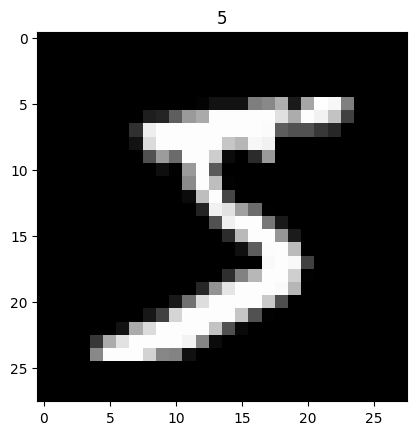

In [6]:
import matplotlib.pyplot as plt

plt.imshow(X[0].reshape(28, 28), cmap="gray")
plt.title(y[0])
plt.show()

In [7]:
# Hold out 20% for validation; use the same split for every learning rate.
Y = np.eye(10)[y]
indices = np.random.default_rng(42).permutation(len(X))
split = int(0.8 * len(X))
train_indices, val_indices = indices[:split], indices[split:]
images = X.reshape(-1, 1, 28, 28)
X_train, Y_train = images[train_indices], Y[train_indices]
X_val, Y_val = images[val_indices], Y[val_indices]


In [8]:
from src.layers import DenseLayer, ActivationLayer, ConvolutionalLayer, FlattenLayer
from src.activations import Activation
from src.losses import Loss
from src.network import nn_forward
from src.learn import learn


In [ ]:
import matplotlib.pyplot as plt

EPOCHS = 5
for learning_rate in [1]:

    np.random.seed(42)
    layers = [
        ConvolutionalLayer(1, 8, 3), # 26X26
        ActivationLayer(Activation.RELU),
        ConvolutionalLayer(8, 3, 3), # 24X24
        ActivationLayer(Activation.RELU),
        FlattenLayer((3, 24, 24)), # 24*24*3 = 1728
        DenseLayer(1728, 128),
        ActivationLayer(Activation.RELU),
        DenseLayer(128, 10),
        ActivationLayer(Activation.SOFTMAX),
    ]

    losses, val_losses, weights = learn(
        EPOCHS, X_train, Y_train, learning_rate, layers,
        X_val, Y_val, loss_f=Loss.CROSS_ENTROPY, print_rate=1, batch_size=128
    )
    plt.figure()
    plt.plot(range(EPOCHS), losses, label="In-sample (training)")
    plt.plot(range(EPOCHS), val_losses, label="OOS (validation)")
    plt.xlabel("Epoch (after updates)")
    plt.ylabel("Mean cross-entropy loss")
    plt.title(f"Training and validation loss — learning rate {learning_rate}")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# Save final trained parameters for Python and the drawing interface.
from train_export import save_model

validation_predictions = nn_forward(X_val, weights)[-1]
metrics = {
    'validation_loss': float(Loss.CROSS_ENTROPY.forward(validation_predictions, Y_val)),
    'validation_accuracy': float(np.mean(validation_predictions.argmax(axis=1) == Y_val.argmax(axis=1))),
    'train_samples': len(X_train),
    'validation_samples': len(X_val),
}
save_model(weights, EPOCHS, learning_rate, metrics)
print("Saved trained weights and digit-web/dist/model.json")
